In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

url = "https://raw.githubusercontent.com/MahimaSriK/Mall-Customer-Segmentation-Dataset/main/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe().round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate rows: 0

Summary statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [4]:
features = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("Features prepared:", X_scaled.shape)
print("Standardisation complete.")

Features prepared: (200, 2)
Standardisation complete.


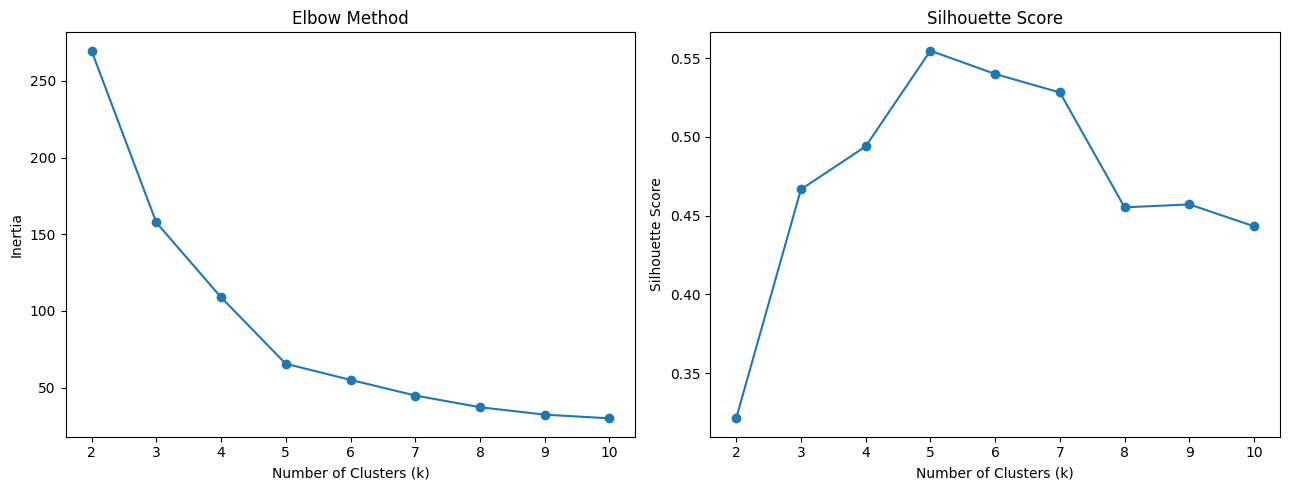

Silhouette scores:
k = 2: 0.321
k = 3: 0.467
k = 4: 0.494
k = 5: 0.555
k = 6: 0.540
k = 7: 0.528
k = 8: 0.455
k = 9: 0.457
k = 10: 0.443


In [5]:

from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(range(2, 11), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(range(2, 11), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k = {k}: {score:.3f}")


In [6]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers in each cluster:")
display(df["Cluster"].value_counts().sort_index())

Customers in each cluster:


,count
Cluster,
0,81
1,39
2,22
3,35
4,23


In [7]:
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


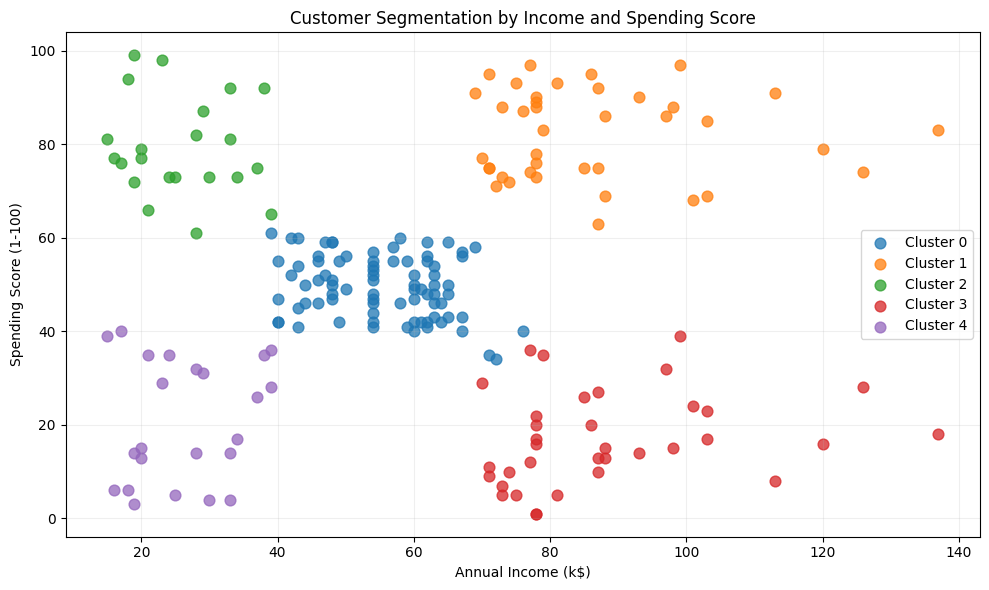

In [8]:

plt.figure(figsize=(10, 6))

for cluster in sorted(df["Cluster"].unique()):
    segment = df[df["Cluster"] == cluster]
    plt.scatter(
        segment["Annual Income (k$)"],
        segment["Spending Score (1-100)"],
        label=f"Cluster {cluster}",
        s=60,
        alpha=0.75
    )

plt.title("Customer Segmentation by Income and Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [9]:

segment_names = {
    0: "Average Income, Average Spending",
    1: "High Income, High Spending",
    2: "Low Income, High Spending",
    3: "High Income, Low Spending",
    4: "Low Income, Low Spending"
}

cluster_summary["Segment"] = cluster_summary.index.map(segment_names)
cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(df) * 100
).round(1)

display(
    cluster_summary[
        ["Segment", "Customer_Count", "Customer_Percentage",
         "Average_Age", "Average_Income", "Average_Spending_Score"]
    ].sort_values("Customer_Count", ascending=False)
)


,Segment,Customer_Count,Customer_Percentage,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,,,
0,"Average Income, Average Spending",81,40.5,42.72,55.30,49.52
1,"High Income, High Spending",39,19.5,32.69,86.54,82.13
3,"High Income, Low Spending",35,17.5,41.11,88.20,17.11
4,"Low Income, Low Spending",23,11.5,45.22,26.30,20.91
2,"Low Income, High Spending",22,11.0,25.27,25.73,79.36


## Business Insights and Recommendations

### Key Findings

- **The largest segment:** Average-income, average-spending customers account for 40.5% of the dataset. Because they represent the largest group, the business could test loyalty programmes and targeted promotions to understand what encourages repeat engagement.
- **High-income, high-spending customers:** This segment represents 19.5% of customers and has the highest average spending score (82.13). Personalised offers and retention initiatives may help maintain their engagement.
- **High-income, low-spending customers:** Representing 17.5% of customers, this group has the highest average annual income (88.20k) but a low average spending score (17.11). The business could test relevant offers and gather feedback to better understand their shopping preferences.
- **Low-income, high-spending customers:** Although this is the smallest segment at 11.0%, its average spending score is 79.36. Accessible promotions and loyalty rewards could be explored.
- **Low-income, low-spending customers:** This group represents 11.5% of customers. Value-oriented promotions could be tested to determine whether they improve engagement.

### Limitations

This analysis uses annual income and spending score to group customers. The spending score is not actual transaction spending, revenue or profit. The dataset also does not explain why customers behave in particular ways, and the findings should not be generalised to every retail business. The recommendations are therefore hypotheses to test, not guaranteed outcomes.

### Conclusion

K-Means clustering identified five customer segments with distinct income and spending-score patterns. These segments provide a starting point for more tailored marketing strategies and customer engagement. Further analysis using transaction history, product preferences and customer responses would help validate the recommendations and measure their effectiveness.